In [13]:
import numpy as np
import matplotlib.pyplot as plt
import scipy.stats as stats
import pandas as pd
import seaborn as sns

# Monitoria 09/09/2025

# 1. Princípios de planejamento de experimentos

A experimentação faz parte de praticamente qualquer área do conhecimento. Em certas situações, para que possam ser tiradas conclusões sobre o funcionamento de algo não basta apenas observar. Em certas situações, é necessário que o pesquisador faça modificações no seu objeto de estudo para que de fato fique claro os efeitos que aquela mudança teve sobre seu resultado. De fato, associamos naturalmente a ideia de um experimento a um contexto controlado e organizado. Uma outra palavra intimamente ligada, no senso comum, à palavra experimento é a palavra teste. Não coincidentemente, essa é a nomenclatura utilizada no contexto estatístico. O desenvolvimento de testes de hipóteses teve como base a possibilidade de tirar conclusões exatas sobre o mundo, mas de forma a ainda manter um rigor matemático e científico.

Um experimento pode ser representado no geral pelo seguinte diagrama:

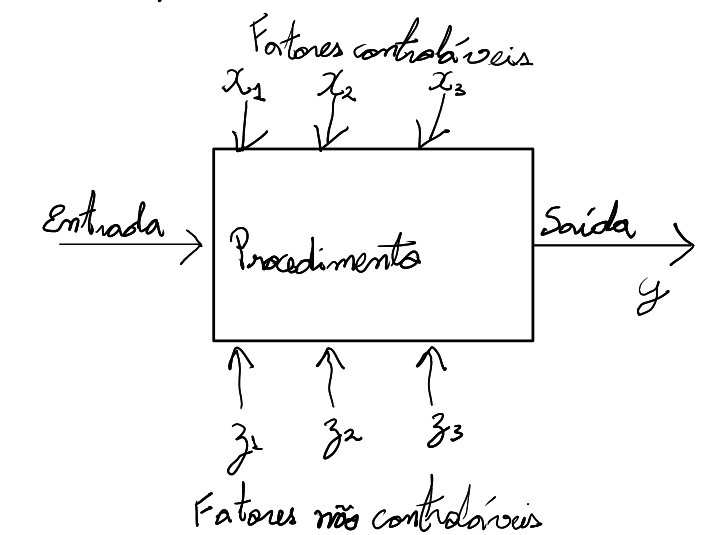

No geral, temos uma ou mais variáveis de interesse, que são denotadas na imagem acima por $y$, a(s) qual(is) depende(m) de uma séries de outros fatores, que podem ser controláveis (voltagem em um circuito, temperatura local, quantidade de adubo) ou incontroláveis (clima de uma região, reação de um ser humano, tempo de chuva). O pensamento crítico científico surge ao considerarmos formas de quantificar corretamente a nossa variável de interesse às demais variáveis, de modo a identificar interações entre as variáveis controláveis e possivelmente mitigar os efeitos de variáveis incontroláveis da análise.

O planejamento de experimentos conta com três princípios básicos:

* Casualização: Tanto a alocação dos materiais quanto a ordem em que os experimentos são feitos deve ser estabelecida aleatoriamente.
    * Garantir observações independentes;
    * Amenizar os efeitos de fatores externos que não são considerados na análise; (O próprio cansaço do experimentador, por exemplo);
* Replicação (medidas repetidas): Para cada combinação de fatores testados, é indicado tomar várias medidas. Isso nos garante o estudo da variabilidade inerente do processo. Ou seja, mesmo que controlamos todos os fatores de entrada, ainda sim observamos resultados diferentes entre si. Este erro é usado no contexto de regressão como "erro puro".
* Blocagem: Suponha que temos o interesse em testar dois tipos de fertilizantes em uma plantação. Para isso, traçamos um experimento que consiste em aplicar o produto A em metade do campo e o produto B na outra metade. Infelizmente, fora do nosso controle, uma região do campo recebe mais incidência de sol que a outra. Sendo assim, separamos a região com mais incidência e com menos incidência, aplicando ambos os fertilizantes A e B em ambas as regiões. Fatores externos que não podem ser controlados experimentalmente ainda podem ser mitigados através da criação de blocos.

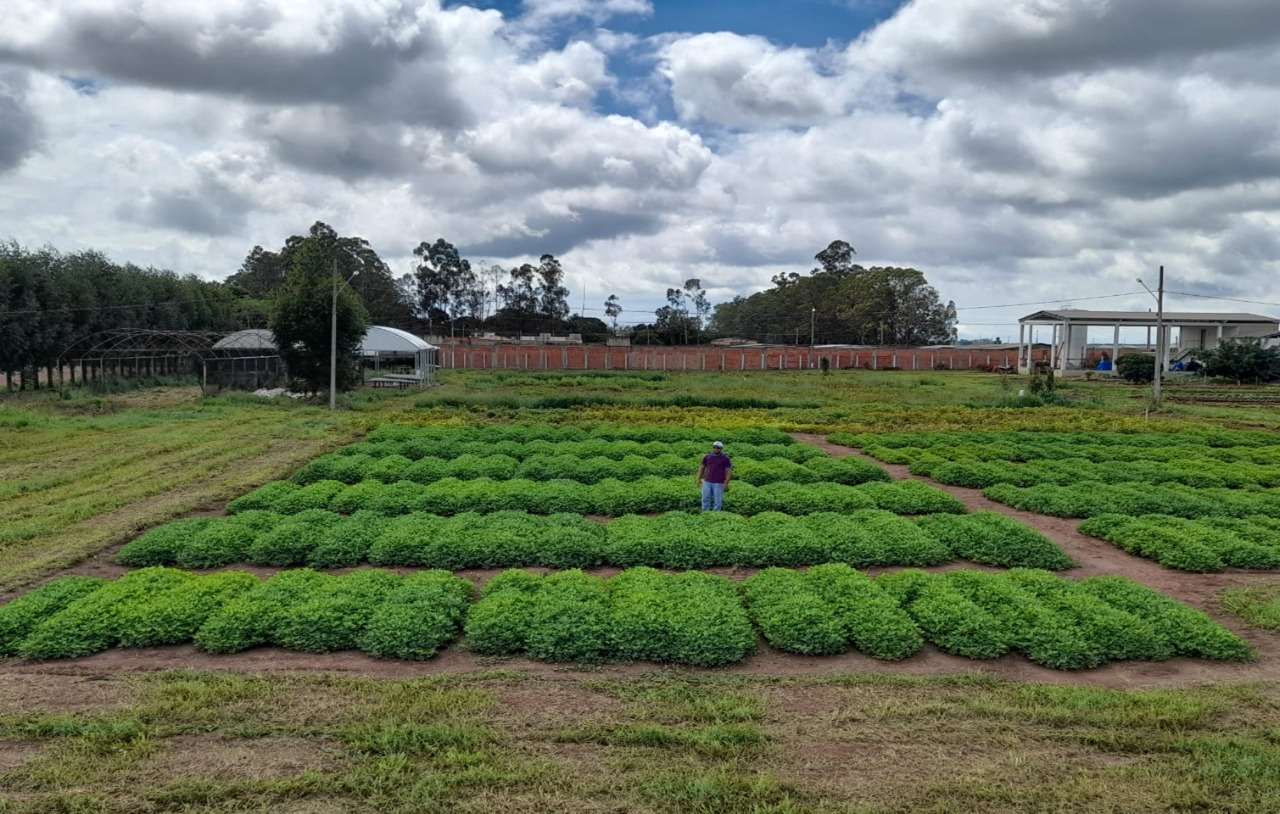

Fonte: https://www.southamericansciences.com.br/index.php/sas/article/view/114

# 2. Montando um experimento

# 3. Exemplo do Montgomery

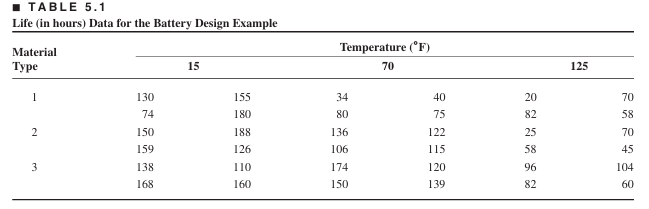

In [14]:
df = pd.DataFrame({
    "Material": [1]*12 + [2]*12 + [3]*12,
    "Temperatura": (
        [15]*4 + [70]*4 + [125]*4 +
        [15]*4 + [70]*4 + [125]*4 +
        [15]*4 + [70]*4 + [125]*4
    ),
    "Tempo": [
        # Material 1
        130, 74, 155, 180,   34, 80, 40, 75,   20, 82, 70, 58,
        # Material 2
        150, 159, 188, 126,  136, 106, 122, 115,  25, 58, 70, 45,
        # Material 3
        138, 168, 110, 160,  174, 150, 120, 139,  96, 82, 104, 60
    ]
})
df.head()

,Material,Temperatura,Tempo
0,1,15,130
1,1,15,74
2,1,15,155
3,1,15,180
4,1,70,34


In [15]:
import statsmodels.api as sm
from statsmodels.formula.api import ols

model = ols('Tempo ~ C(Material) * C(Temperatura)', data=df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)

anova_table

,sum_sq,df,F,PR(>F)
C(Material),10683.722222,2.0,7.911372,1.976083e-03
C(Temperatura),39118.722222,2.0,28.967692,1.908596e-07
C(Material):C(Temperatura),9613.777778,4.0,3.559535,1.861117e-02
Residual,18230.750000,27.0,NaN,NaN


In [16]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=df['Tempo'], groups=df['Temperatura'], alpha=0.05)
print(tukey)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
    15     70   -37.25 0.0305  -71.4791  -3.0209   True
    15    125 -80.6667    0.0 -114.8957 -46.4376   True
    70    125 -43.4167 0.0104  -77.6457  -9.1876   True
-------------------------------------------------------


<Axes: xlabel='Temperatura', ylabel='Tempo'>

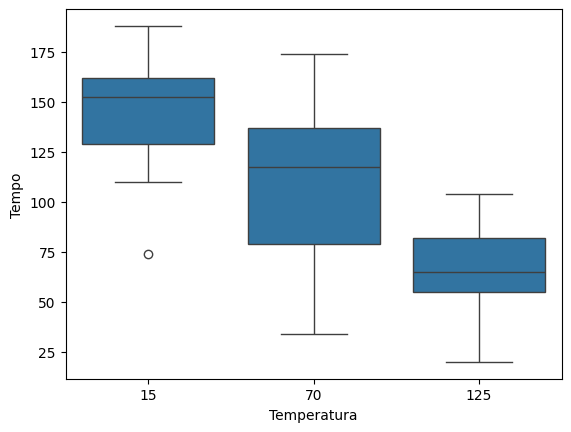

In [17]:
sns.boxplot(x ='Temperatura', y = 'Tempo', data = df)

In [18]:
df["Mat_Temp"] = df['Material'].astype(str) + '_' + df['Temperatura'].astype(str)
df.head()

,Material,Temperatura,Tempo,Mat_Temp
0,1,15,130,1_15
1,1,15,74,1_15
2,1,15,155,1_15
3,1,15,180,1_15
4,1,70,34,1_70


In [19]:
tukey = pairwise_tukeyhsd(endog=df['Tempo'], groups=df['Mat_Temp'], alpha=0.05)
print(tukey)

  Multiple Comparison of Means - Tukey HSD, FWER=0.05  
group1 group2 meandiff p-adj    lower    upper   reject
-------------------------------------------------------
 1_125   1_15    77.25 0.0067   15.4268 139.0732   True
 1_125   1_70    -0.25    1.0  -62.0732  61.5732  False
 1_125  2_125     -8.0    1.0  -69.8232  53.8232  False
 1_125   2_15    98.25 0.0004   36.4268 160.0732   True
 1_125   2_70    62.25 0.0475    0.4268 124.0732   True
 1_125  3_125     28.0 0.8347  -33.8232  89.8232  False
 1_125   3_15     86.5 0.0019   24.6768 148.3232   True
 1_125   3_70    88.25 0.0015   26.4268 150.0732   True
  1_15   1_70    -77.5 0.0065 -139.3232 -15.6768   True
  1_15  2_125   -85.25 0.0022 -147.0732 -23.4268   True
  1_15   2_15     21.0 0.9616  -40.8232  82.8232  False
  1_15   2_70    -15.0 0.9953  -76.8232  46.8232  False
  1_15  3_125   -49.25 0.2017 -111.0732  12.5732  False
  1_15   3_15     9.25 0.9999  -52.5732  71.0732  False
  1_15   3_70     11.0 0.9995  -50.8232  72.8232

<Axes: xlabel='Temperatura', ylabel='Tempo'>

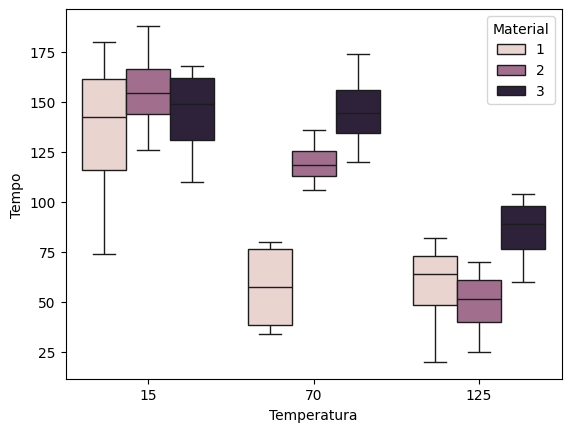

In [20]:
sns.boxplot(x ='Temperatura', y = 'Tempo', data = df, hue = 'Material')

In [21]:
tukey_df = pd.DataFrame(data=tukey._results_table.data[1:],
                        columns=tukey._results_table.data[0])

alvo = "3_70"

compara_3 = tukey_df[
    (tukey_df['group1'].str.contains(alvo)) | (tukey_df['group2'].str.contains(alvo))
]
print(compara_3)

   group1 group2  meandiff   p-adj    lower     upper  reject
7   1_125   3_70     88.25  0.0015  26.4268  150.0732    True
14   1_15   3_70     11.00  0.9995 -50.8232   72.8232   False
20   1_70   3_70     88.50  0.0014  26.6768  150.3232    True
25  2_125   3_70     96.25  0.0005  34.4268  158.0732    True
29   2_15   3_70    -10.00  0.9997 -71.8232   51.8232   False
32   2_70   3_70     26.00  0.8823 -35.8232   87.8232   False
34  3_125   3_70     60.25  0.0604  -1.5732  122.0732   False
35   3_15   3_70      1.75  1.0000 -60.0732   63.5732   False


In [22]:
group_means = df.groupby("Mat_Temp")["Tempo"].mean().sort_values(ascending=False)
print(group_means)

tukey_df = pd.DataFrame(data=tukey._results_table.data[1:],
                        columns=tukey._results_table.data[0])

# Grupo com a maior media
top_group = group_means.index[0]
top_mean = group_means.iloc[0]

print(f"\nGrupo com a maior media: {top_group} (media = {top_mean:.2f})")

# comparações que envolvem o grupo com a maior media
compara = tukey_df[
    (tukey_df['group1'] == top_group) | (tukey_df['group2'] == top_group)
]

print("\nComparações com o grupo de maior media:")
print(compara)

Mat_Temp
2_15     155.75
3_70     145.75
3_15     144.00
1_15     134.75
2_70     119.75
3_125     85.50
1_125     57.50
1_70      57.25
2_125     49.50
Name: Tempo, dtype: float64

Grupo com a maior media: 2_15 (media = 155.75)

Comparações com o grupo de maior media:
   group1 group2  meandiff   p-adj     lower     upper  reject
3   1_125   2_15     98.25  0.0004   36.4268  160.0732    True
10   1_15   2_15     21.00  0.9616  -40.8232   82.8232   False
16   1_70   2_15     98.50  0.0003   36.6768  160.3232    True
21  2_125   2_15    106.25  0.0001   44.4268  168.0732    True
26   2_15   2_70    -36.00  0.5819  -97.8232   25.8232   False
27   2_15  3_125    -70.25  0.0172 -132.0732   -8.4268    True
28   2_15   3_15    -11.75  0.9991  -73.5732   50.0732   False
29   2_15   3_70    -10.00  0.9997  -71.8232   51.8232   False


In [23]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(endog=df['Tempo'], groups=df['Material'], alpha=0.05)
print(tukey)

 Multiple Comparison of Means - Tukey HSD, FWER=0.05 
group1 group2 meandiff p-adj   lower    upper  reject
-----------------------------------------------------
     1      2  25.1667 0.3687  -19.959 70.2924  False
     1      3  41.9167 0.0729   -3.209 87.0424  False
     2      3    16.75 0.6374 -28.3757 61.8757  False
-----------------------------------------------------


<Axes: xlabel='Material', ylabel='Tempo'>

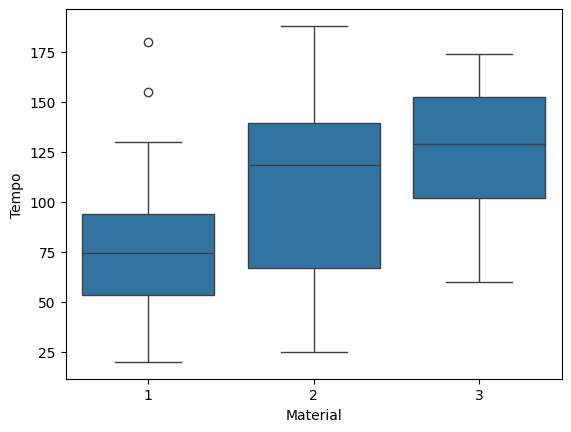

In [24]:
sns.boxplot(x ='Material', y = 'Tempo', data = df)

Montgomery, D.C. Design and Analysis of Experiments, Willey, 9th Edition, 2017.